In [16]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Load the Karate Club dataset
G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()

# Construct global modularity matrix B = A - (k * k^T) / (2m)
A = nx.to_numpy_array(G)
deg = np.sum(A, axis=1).reshape(-1, 1)
B = A - (deg @ deg.T) / (2 * m)

# Fix node coordinates so plots stay consistent across splits
layout = nx.spring_layout(G, seed=10)

In [17]:
def get_node_metrics(communities):
    # Build a graph keeping only edges inside the same community
    G_split = nx.Graph()
    G_split.add_nodes_from(G.nodes())
    for c in communities:
        G_split.add_edges_from(G.subgraph(c).edges())

    return {
        "degree": nx.degree_centrality(G_split),
        "betweenness": nx.betweenness_centrality(G_split),
        "closeness": nx.closeness_centrality(G_split),
        "clustering": nx.clustering(G_split)
    }

def draw_split(communities, step):
    plt.figure(figsize=(7, 5))
    palette = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#76b7b2", "#edc948"]

    for i, comm in enumerate(communities):
        nx.draw_networkx_nodes(
            G, layout,
            nodelist=comm,
            node_color=palette[i % len(palette)],
            node_size=400,
            label=f"Group {i+1}"
        )

    nx.draw_networkx_edges(G, layout, alpha=0.35)
    nx.draw_networkx_labels(G, layout, font_size=8, font_color="white")
    plt.title(f"Split Step {step} ({len(communities)} communities)")
    plt.legend()
    plt.axis("off")
    plt.show()

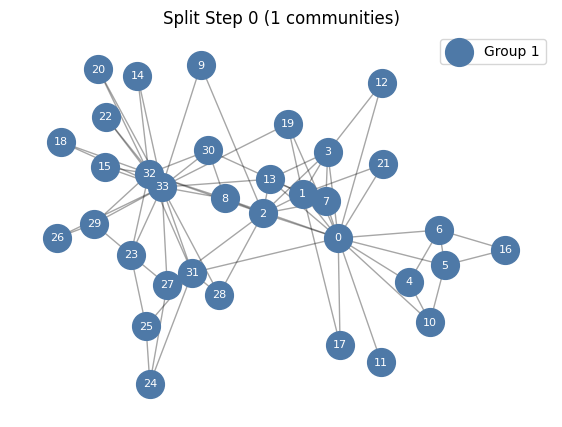

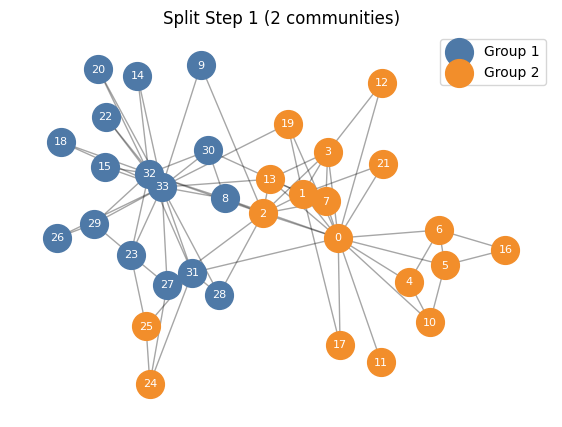

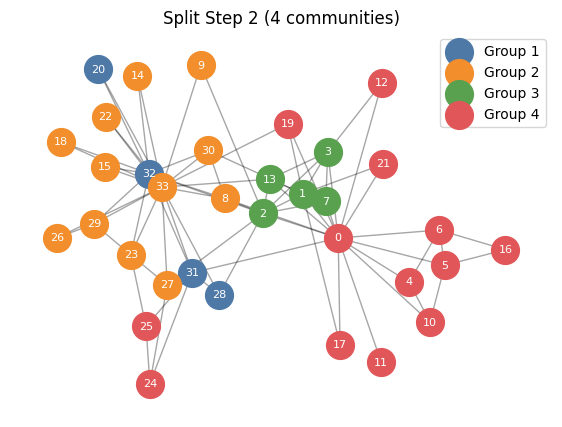

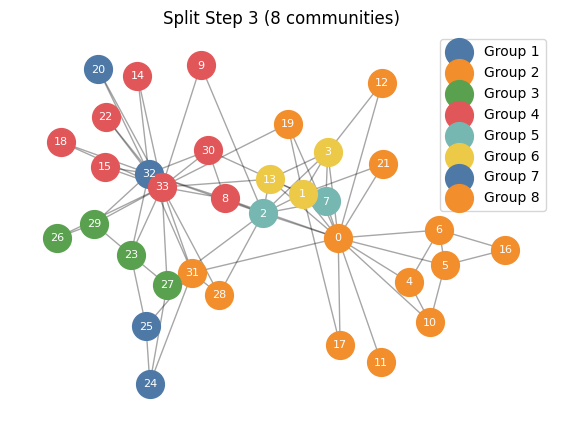

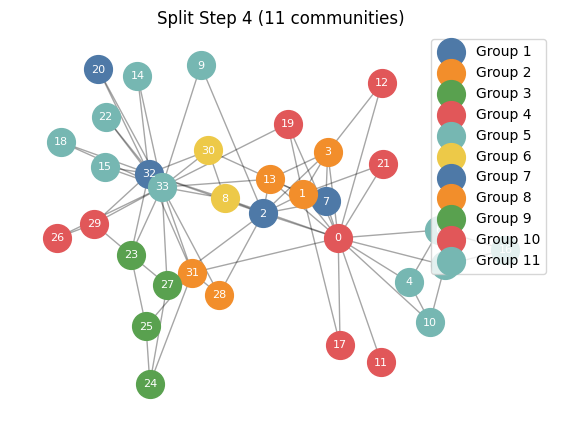

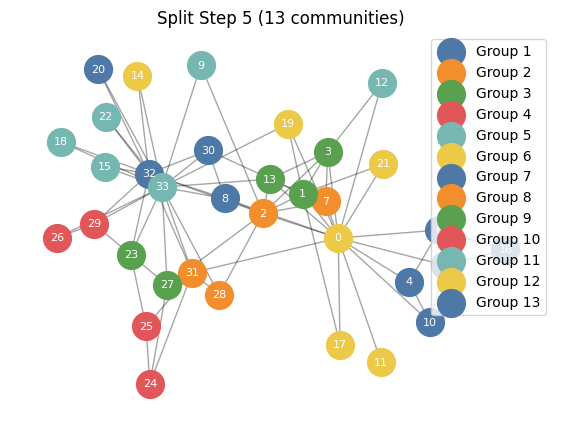

Final communities:
Group 1: [20, 32]
Group 2: [28, 31]
Group 3: [23, 27]
Group 4: [26, 29]
Group 5: [9, 15, 18, 22, 33]
Group 6: [14]
Group 7: [8, 30]
Group 8: [2, 7]
Group 9: [1, 3, 13]
Group 10: [24, 25]
Group 11: [12]
Group 12: [0, 11, 17, 19, 21]
Group 13: [4, 5, 6, 10, 16]


In [18]:
groups = [list(G.nodes())]
step = 0

# Track metrics at step 0 (before any split)
history = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
initial_metrics = get_node_metrics(groups)
for name in history:
    history[name][step] = initial_metrics[name]

draw_split(groups, step)

while True:
    updated_groups = []
    did_split = False

    for g in groups:
        if len(g) <= 1:
            updated_groups.append(g)
            continue

        # Restrict B to subgraph g and adjust diagonal (Newman's generalized matrix)
        B_sub = B[np.ix_(g, g)].copy()
        np.fill_diagonal(B_sub, B_sub.diagonal() - np.sum(B_sub, axis=1))

        vals, vecs = np.linalg.eigh(B_sub)
        max_val = vals[-1]
        max_vec = vecs[:, -1]

        # Stop splitting this group if leading eigenvalue <= 0
        if max_val > 1e-8:
            g_pos = [g[i] for i in range(len(g)) if max_vec[i] > 0]
            g_neg = [g[i] for i in range(len(g)) if max_vec[i] <= 0]

            if len(g_pos) > 0 and len(g_neg) > 0:
                updated_groups.extend([g_pos, g_neg])
                did_split = True
            else:
                updated_groups.append(g)
        else:
            updated_groups.append(g)

    if not did_split:
        break

    step += 1
    groups = updated_groups

    step_metrics = get_node_metrics(groups)
    for name in history:
        history[name][step] = step_metrics[name]

    draw_split(groups, step)

print("Final communities:")
for i, g in enumerate(groups, 1):
    print(f"Group {i}: {sorted(g)}")

### Discussion

**Method Reference:**  
This implementation uses the recursive spectral modularity algorithm from M. E. J. Newman, *"Modularity and community structure in networks,"* PNAS 103(23): 8577–8582 (2006)[cite: 7].

**Observations on Central Nodes and Metric Changes:**  
Throughout the splits, nodes **0** (the instructor) and **33** (the club president), along with **1**, **2**, and **32**, stay the most central nodes inside their respective groups. Even after the first split separates the two main factions, nodes 0 and 33 keep the largest number of internal connections, so they remain the local hubs in their communities.

As the graph splits into smaller communities, the four metrics change in distinct ways:
* **Betweenness centrality** drops the most sharply. In the full graph, nodes sitting between the two factions (such as node 2 and node 31) carry many shortest paths across the network. Once those cross-community edges are removed, those shortest paths no longer exist, leaving only local hubs with moderate betweenness inside their own clusters.
* **Degree and closeness centrality** decrease across iterations because cutting inter-community edges reduces each node's total active neighbors and disconnects the subgraphs from one another. However, the relative ranking of nodes within each cluster stays roughly the same.
* **Clustering coefficient** stays relatively stable or increases slightly for tightly connected members, since modularity partitioning removes sparse bridges between groups while leaving dense local triangles intact.